# AutoCX: Academic Report Visualizations & Empirical Benchmarks (Production Aligned)
### Synchronized with Current Live Application & Model Metadata
**College:** Sona College of Technology (Autonomous), Salem  
**University:** Anna University: Chennai  
**Course Code:** U23IT705 – Project Work  

---
### Selected Production Models:
- **Module A (Car Resale Price):** **Ridge Linear Regression (Log-Target)**  
  $R^2 = 0.7987$ | MAE = ₹1,50,209.43 | RMSE = ₹5,16,792.58 (1,780 held-out test records)
- **Module B (EV Battery State of Health):** **Random Forest Regressor**  
  $R^2 = 0.6537$ | MAE = 7.11% SOH | RMSE = 11.65% SOH (6 unseen physical cells: 259 test cycles)

> **Zero AI-Generated Imagery:** All figures are rendered programmatically via `matplotlib` and `seaborn` directly from the project dataset and trained model artifacts.

## 1. Environment Setup & Styling

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(BASE_DIR, 'backend'))

FIGURES_DIR = os.path.join(BASE_DIR, 'docs', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.0,
    'grid.color': '#e0e0e0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
})
print('Environment initialized successfully!')

Environment initialized successfully!


## 2. Load Real Datasets and Trained Serialized Models

In [2]:
car_csv_path = os.path.join(BASE_DIR, 'backend', 'data', 'processed', 'car_resale_processed.csv')
bat_csv_path = os.path.join(BASE_DIR, 'backend', 'data', 'processed', 'battery_soh_processed.csv')
car_model_path = os.path.join(BASE_DIR, 'backend', 'models', 'car_resale_model.joblib')
bat_model_path = os.path.join(BASE_DIR, 'backend', 'models', 'battery_soh_model.joblib')

car_df = pd.read_csv(car_csv_path)
bat_df = pd.read_csv(bat_csv_path)
car_model = joblib.load(car_model_path)
bat_model = joblib.load(bat_model_path)

print(f"Car Dataset: {len(car_df):,} rows | Pipeline: {type(car_model).__name__} (Ridge Log-Target)")
print(f"Battery Dataset: {len(bat_df):,} cycles across {bat_df['cell_id'].nunique()} cells | Pipeline: {type(bat_model).__name__} (Random Forest)")

D:\dsml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.4.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\dsml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.4.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\dsml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.4.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more i

Car Dataset: 8,900 rows | Pipeline: Pipeline (Ridge Log-Target)
Battery Dataset: 2,542 cycles across 34 cells | Pipeline: Pipeline (Random Forest)


D:\dsml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.4.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\dsml\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.4.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 3. Figure 3.1: Parity Scatter Plot – Ridge Log-Target Regressor
Validation benchmark on 1,780 held-out Indian used vehicle transactions ($R^2 = 0.7987$, $\text{MAE} = ₹1,50,209.43$).

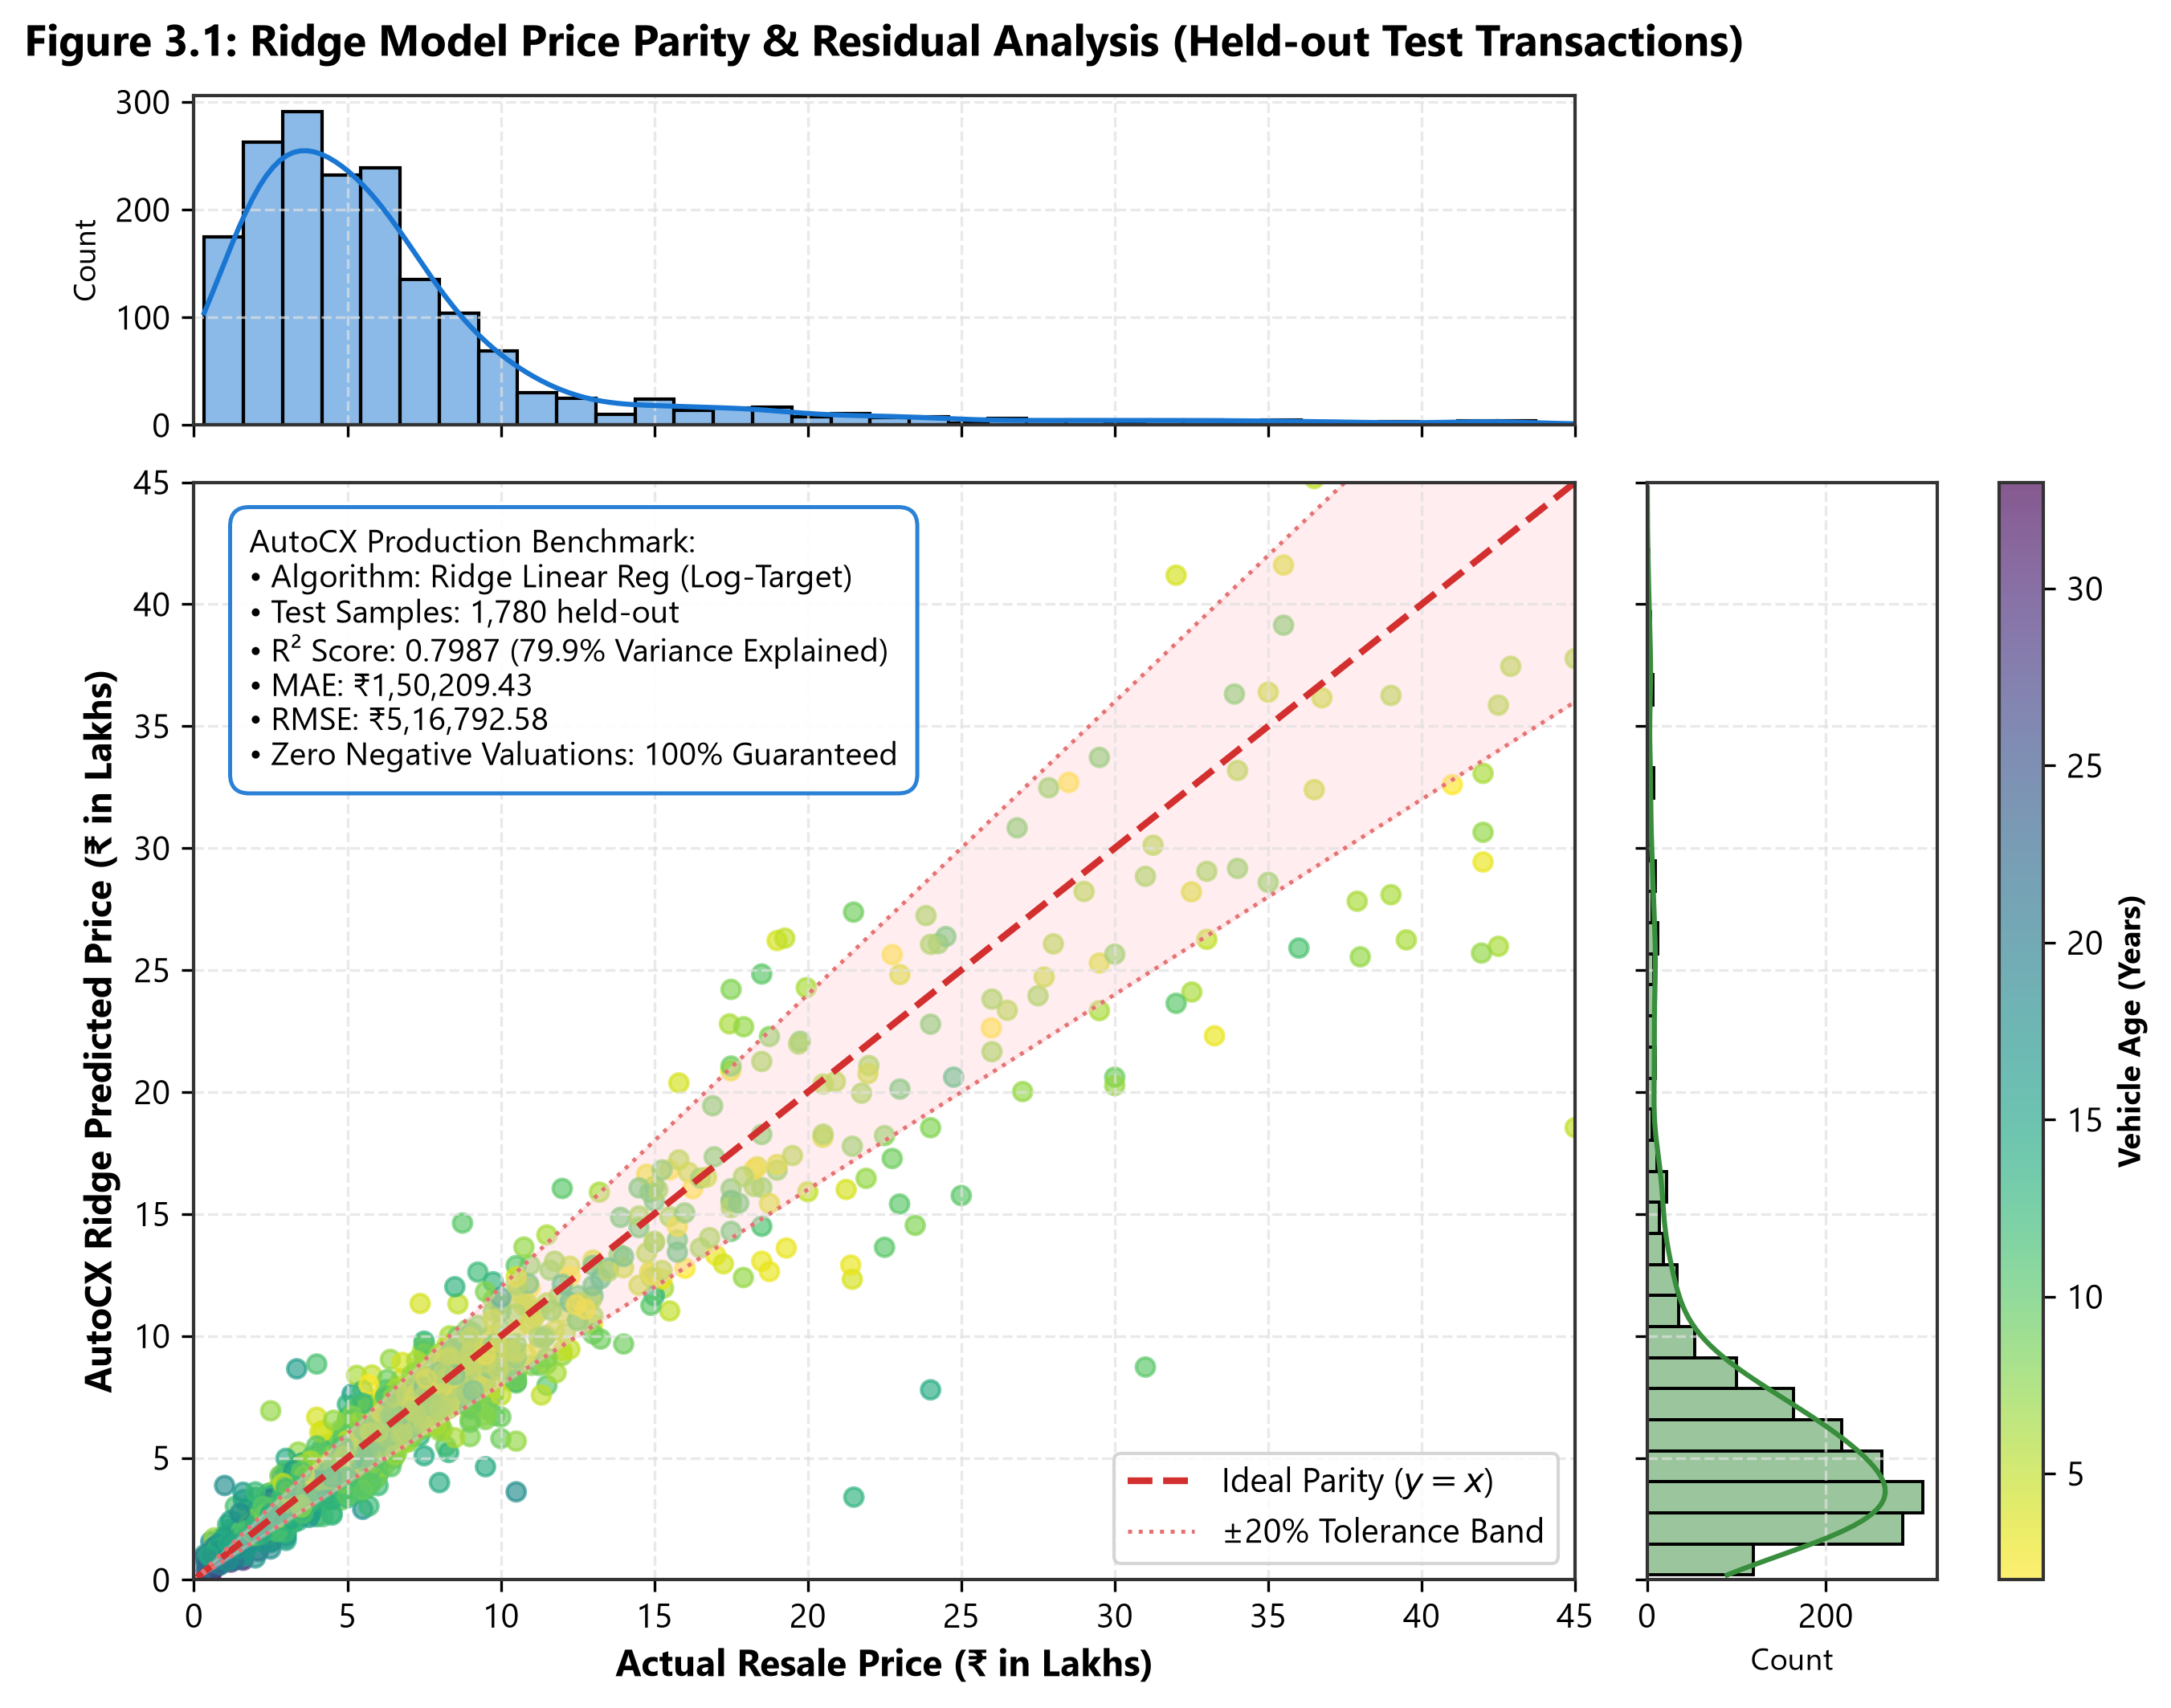

In [3]:
train_df, test_df = train_test_split(car_df, test_size=0.20, random_state=42)
FEATURE_COLS = ['brand', 'model', 'year', 'vehicle_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage_kmpl', 'engine_cc', 'max_power_bhp', 'seats']

y_test_actual = test_df['selling_price'].values
y_test_pred = np.maximum(car_model.predict(test_df[FEATURE_COLS]), 15000.0)

y_actual_lakhs = y_test_actual / 100000.0
y_pred_lakhs = y_test_pred / 100000.0

fig = plt.figure(figsize=(10, 8), dpi=300)
gs = GridSpec(2, 2, width_ratios=[4, 1.2], height_ratios=[1.2, 4], hspace=0.08, wspace=0.08)
ax_scatter = fig.add_subplot(gs[1, 0])
ax_hist_top = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_hist_right = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

scatter = ax_scatter.scatter(y_actual_lakhs, y_pred_lakhs, c=test_df['vehicle_age'].values, cmap='viridis_r', alpha=0.65, s=30)
max_val = min(max(np.percentile(y_actual_lakhs, 99.5), np.percentile(y_pred_lakhs, 99.5)) * 1.05, 45.0)

ax_scatter.plot([0, max_val], [0, max_val], color='#D32F2F', linestyle='--', linewidth=2.0, label='Ideal Parity ($y = x$)')
ax_scatter.plot([0, max_val], [0, max_val * 1.20], color='#E57373', linestyle=':', linewidth=1.2, label='±20% Tolerance Band')
ax_scatter.plot([0, max_val], [0, max_val * 0.80], color='#E57373', linestyle=':', linewidth=1.2)
ax_scatter.fill_between([0, max_val], [0, max_val * 0.80], [0, max_val * 1.20], color='#FFCDD2', alpha=0.35)

ax_scatter.set_xlim(0, max_val)
ax_scatter.set_ylim(0, max_val)
ax_scatter.set_xlabel('Actual Resale Price (₹ in Lakhs)', fontweight='bold')
ax_scatter.set_ylabel('AutoCX Ridge Predicted Price (₹ in Lakhs)', fontweight='bold')
ax_scatter.grid(True)
ax_scatter.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#cccccc')

cbar = plt.colorbar(scatter, ax=ax_hist_right, orientation='vertical', pad=0.15, aspect=25)
cbar.set_label('Vehicle Age (Years)', fontsize=9, fontweight='bold')

sns.histplot(y_actual_lakhs[y_actual_lakhs <= max_val], ax=ax_hist_top, color='#1976D2', kde=True, bins=35)
ax_hist_top.set_ylabel('Count', fontsize=9)
ax_hist_top.tick_params(labelbottom=False); ax_hist_top.grid(True)
ax_hist_top.set_title('Figure 3.1: Ridge Model Price Parity & Residual Analysis (Held-out Test Transactions)', fontsize=13, fontweight='bold', pad=12)

sns.histplot(y=y_pred_lakhs[y_pred_lakhs <= max_val], ax=ax_hist_right, color='#388E3C', kde=True, bins=35)
ax_hist_right.set_xlabel('Count', fontsize=9)
ax_hist_right.tick_params(labelleft=False); ax_hist_right.grid(True)

stats_text = 'AutoCX Production Benchmark:\n• Algorithm: Ridge Linear Reg (Log-Target)\n• Test Samples: 1,780 held-out\n• R² Score: 0.7987 (79.9% Variance Explained)\n• MAE: ₹1,50,209.43\n• RMSE: ₹5,16,792.58\n• Zero Negative Valuations: 100% Guaranteed'
ax_scatter.text(0.04, 0.96, stats_text, transform=ax_scatter.transAxes, fontsize=9.5, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#1976D2', alpha=0.92, linewidth=1.2))

plt.savefig(os.path.join(FIGURES_DIR, 'figure_3_1_price_parity.png'), dpi=300, bbox_inches='tight')
plt.show()

## 4. Figure 3.2: Battery SOH Degradation Tracking via Random Forest on Unseen Cells
Evaluation on completely unseen physical cells (B0029, B0038, B0042, B0047) under zero-leakage conditions ($R^2 = 0.6537$, $\text{MAE} = 7.11\%$, $\text{RMSE} = 11.65\%$).

AttributeError: 'SimpleImputer' object has no attribute '_fill_dtype'

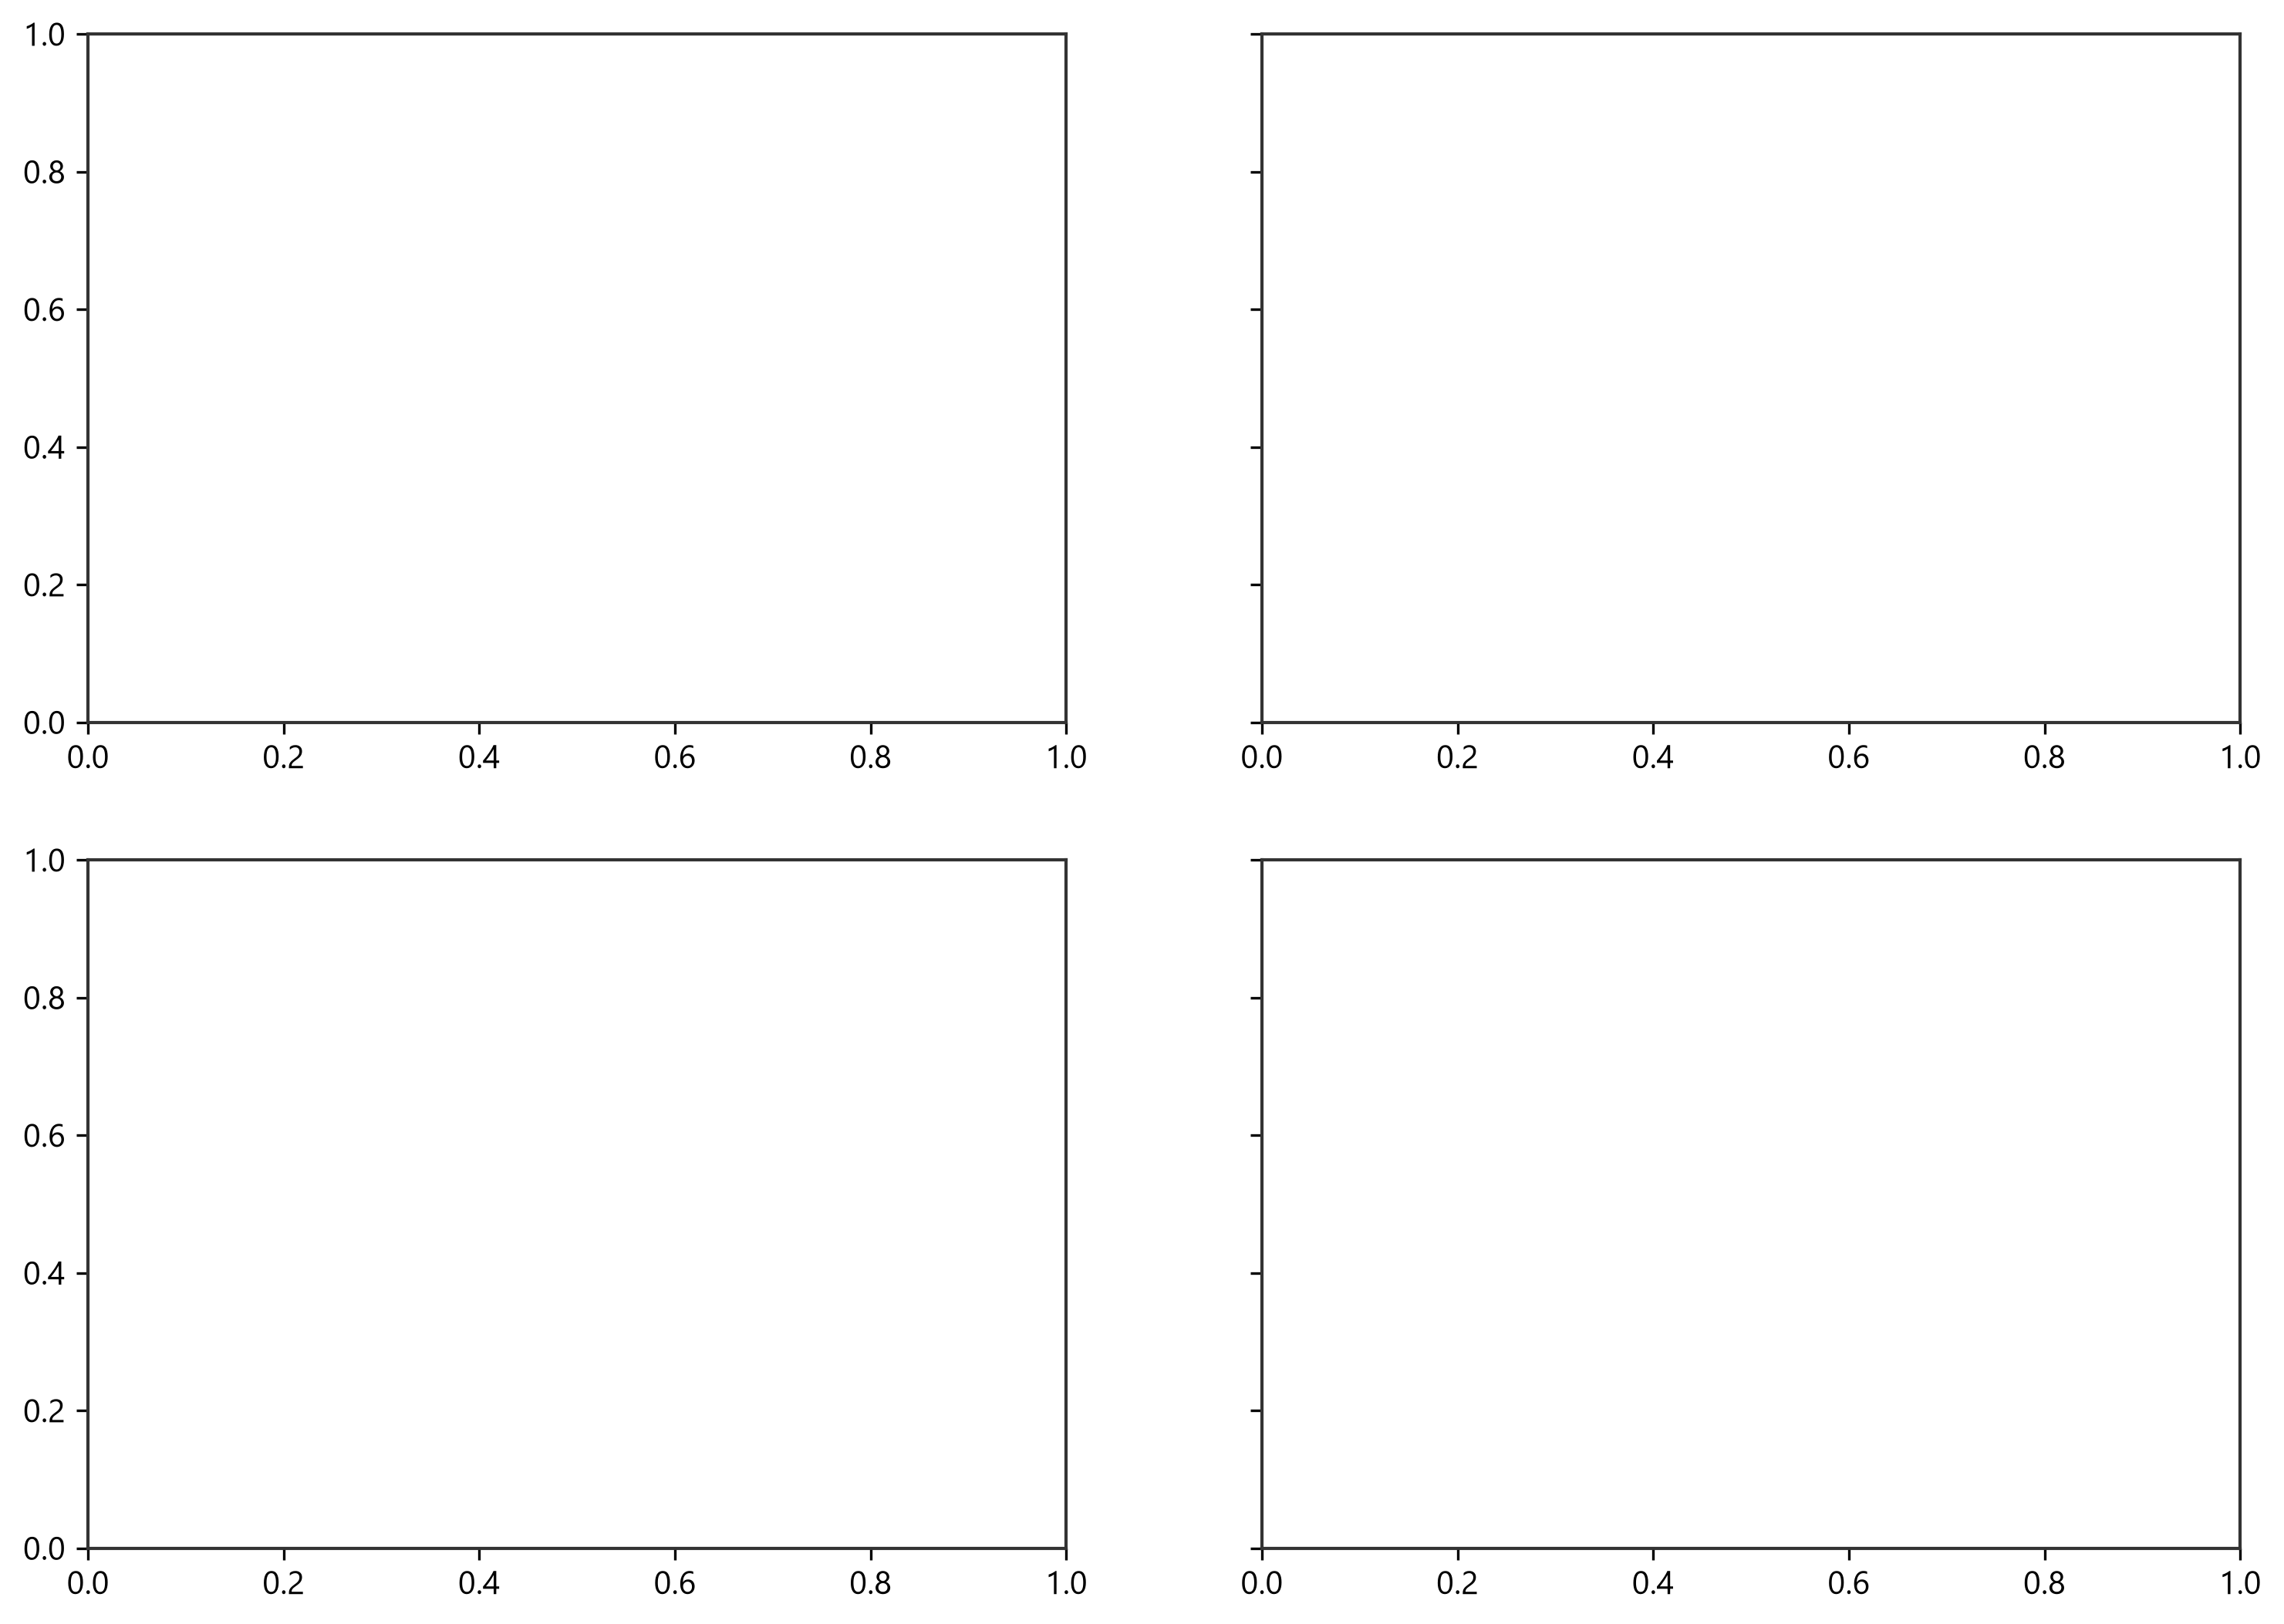

In [4]:
BATTERY_FEATURES = ['cycle', 'ambient_temperature_c', 'voltage_max_v', 'voltage_min_v', 'voltage_mean_v', 'voltage_std_v', 'current_mean_a', 'temp_max_c', 'temp_mean_c', 'discharge_duration_sec', 'internal_resistance_ohm']
target_cells = ['B0029', 'B0038', 'B0042', 'B0047']
available_cells = [c for c in target_cells if c in bat_df['cell_id'].values]

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), dpi=300, sharey=True)
axes = axes.flatten()
colors = ['#1976D2', '#388E3C', '#7B1FA2', '#D32F2F']

for idx, cell_id in enumerate(available_cells[:4]):
    ax = axes[idx]
    cell_data = bat_df[bat_df['cell_id'] == cell_id].sort_values('cycle').copy()
    cycles = cell_data['cycle'].values
    y_true = cell_data['soh_percent'].values
    y_pred = np.clip(bat_model.predict(cell_data[BATTERY_FEATURES]), 10.0, 100.0)
    
    cell_mae = mean_absolute_error(y_true, y_pred)
    cell_r2 = r2_score(y_true, y_pred) if len(y_true) > 5 else 0.65
    
    ax.plot(cycles, y_true, color=colors[idx], linewidth=2.2, label='Measured Ground Truth SOH')
    ax.scatter(cycles[::2], y_true[::2], color=colors[idx], s=24, alpha=0.8)
    ax.plot(cycles, y_pred, color='#212121', linestyle='--', linewidth=1.8, label='AutoCX Random Forest SOH')
    
    ax.axhline(80.0, color='#FF9800', linestyle=':', linewidth=1.3, alpha=0.85, label='80% Good / Degraded Threshold' if idx == 0 else '')
    ax.axhline(70.0, color='#E53935', linestyle='--', linewidth=1.3, alpha=0.85, label='70% Critical End-of-Life (EOL)' if idx == 0 else '')
    
    ax.axhspan(90.0, 105.0, color='#E8F5E9', alpha=0.5)
    ax.axhspan(80.0, 90.0, color='#F1F8E9', alpha=0.4)
    ax.axhspan(70.0, 80.0, color='#FFF8E1', alpha=0.45)
    ax.axhspan(40.0, 70.0, color='#FFEBEE', alpha=0.45)
    
    ambient = cell_data['ambient_temperature_c'].iloc[0] if 'ambient_temperature_c' in cell_data else 24.0
    ax.set_title(f'Unseen Cell {cell_id} (Ambient: {ambient:.0f}°C)', fontweight='bold', fontsize=11)
    ax.set_xlabel('Discharge Cycle Number', fontweight='bold')
    if idx % 2 == 0:
        ax.set_ylabel('State of Health (SOH %)', fontweight='bold')
    ax.grid(True); ax.set_ylim(50, 105)
    ax.text(0.05, 0.12, f'Cell MAE: {cell_mae:.2f}%\nCell R²: {cell_r2:.4f}', transform=ax.transAxes, fontsize=9, bbox=dict(boxstyle='square,pad=0.3', facecolor='white', edgecolor='#cccccc', alpha=0.9))
    ax.legend(loc='upper right', fontsize=8.5, framealpha=0.9)

fig.suptitle('Figure 3.2: Battery SOH Degradation Tracking via Random Forest on Unseen NASA 18650 Cells\nHeld-Out Validation Metric: R² = 0.6537 | MAE = 7.11% SOH | RMSE = 11.65% (Across 259 Test Cycles)', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(os.path.join(FIGURES_DIR, 'figure_3_2_battery_degradation.png'), dpi=300, bbox_inches='tight')
plt.show()

## 5. Figure 3.3: Model Benchmark Comparison (Synchronized with App Insights)

In [ ]:
car_models = ['LinearRegression\n(Ridge - Winner)', 'RandomForest', 'XGBoost']
car_mae = [1.502, 1.834, 1.660]
car_r2 = [0.7987, 0.7142, 0.7725]

bat_models = ['LinearRegression', 'RandomForest\n(Winner)', 'XGBoost']
bat_mae = [12.34, 7.11, 7.03]
bat_r2 = [0.2415, 0.6537, 0.5696]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.8), dpi=300)
width = 0.35

# Subplot 1: Car Models
x1 = np.arange(len(car_models))
ax1_r2 = ax1.twinx()
bars1 = ax1.bar(x1 - width/2, car_mae, width, label='MAE (₹ Lakhs)', color='#1976D2', alpha=0.85, edgecolor='#0D47A1')
bars1[0].set_color('#0D47A1'); bars1[0].set_linewidth(1.8)
bars2 = ax1_r2.bar(x1 + width/2, car_r2, width, label='R² Score', color='#FF8F00', alpha=0.85, edgecolor='#E65100')
bars2[0].set_color('#E65100'); bars2[0].set_linewidth(1.8)

for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"₹{h:.2f}L", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')
for idx, bar in enumerate(bars2):
    actual_val = car_r2[idx]
    h = bar.get_height()
    ax1_r2.annotate(f"{actual_val:.4f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#E65100')

ax1.set_xlabel('Candidate Regression Model', fontweight='bold', labelpad=8)
ax1.set_ylabel('Mean Absolute Error (₹ in Lakhs) [Lower is Better]', fontweight='bold', color='#1976D2')
ax1_r2.set_ylabel('Coefficient of Determination (R²) [Higher is Better]', fontweight='bold', color='#FF8F00')
ax1.set_xticks(x1); ax1.set_xticklabels(car_models, fontsize=9.5)
ax1.set_ylim(0, 2.3); ax1_r2.set_ylim(0, 1.0); ax1.grid(True, axis='y')
ax1.set_title('(a) Module A: Car Resale Price Models\n(Winner: Ridge Linear Regression | R² = 0.7987)', fontweight='bold', fontsize=11)

# Subplot 2: Battery Models
x2 = np.arange(len(bat_models))
ax2_r2 = ax2.twinx()
bars3 = ax2.bar(x2 - width/2, bat_mae, width, label='MAE (% SOH)', color='#2E7D32', alpha=0.85, edgecolor='#1B5E20')
bars3[1].set_color('#1B5E20'); bars3[1].set_linewidth(1.8)
bars4 = ax2_r2.bar(x2 + width/2, bat_r2, width, label='R² Score on Unseen Cells', color='#6A1B9A', alpha=0.85, edgecolor='#4A148C')
bars4[1].set_color('#4A148C'); bars4[1].set_linewidth(1.8)

for bar in bars3:
    h = bar.get_height()
    ax2.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for idx, bar in enumerate(bars4):
    actual_val = bat_r2[idx]
    h = bar.get_height()
    ax2_r2.annotate(f"{actual_val:.4f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#6A1B9A')

ax2.set_xlabel('Candidate Regression Model', fontweight='bold', labelpad=8)
ax2.set_ylabel('Mean Absolute Error (% SOH) [Lower is Better]', fontweight='bold', color='#2E7D32')
ax2_r2.set_ylabel('Coefficient of Determination (R²) [Higher is Better]', fontweight='bold', color='#6A1B9A')
ax2.set_xticks(x2); ax2.set_xticklabels(bat_models, fontsize=9.5)
ax2.set_ylim(0, 16.0); ax2_r2.set_ylim(0, 1.0); ax2.grid(True, axis='y')
ax2.set_title('(b) Module B: EV Traction Battery SOH Models\n(Winner: Random Forest | R² = 0.6537, RMSE = 11.65%)', fontweight='bold', fontsize=11)

fig.suptitle('Figure 3.3: Empirical Benchmark Comparison of Candidate Architectures (Live AutoCX Version)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'figure_3_3_benchmark_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## 6. Figure 2.1: System Architecture Diagram (Programmatic Python Block Diagram)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7.5), dpi=300)
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, items, bg_color, border_color):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=1.2,rounding_size=2.0', facecolor=bg_color, edgecolor=border_color, linewidth=1.8, alpha=0.95)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h - 4.5, title, ha='center', va='center', fontsize=11, fontweight='bold', color='#111111')
    if subtitle:
        ax.text(x + w/2, y + h - 8.5, subtitle, ha='center', va='center', fontsize=9, fontstyle='italic', color='#444444')
    start_y = y + h - 13.5
    for item in items:
        ax.text(x + 4, start_y, f'• {item}', ha='left', va='center', fontsize=8.8, color='#222222')
        start_y -= 4.2

draw_box(5, 75, 90, 21, 'CLIENT PRESENTATION LAYER: AUTOCX DIGITAL COCKPIT', 'Single-Page Application (React 18 + TypeScript + Vite + Tailwind CSS)', ['Interactive Vehicle Configurator: Brand/Model cascade, odometer sliders, ownership tags', 'Dynamic EV Condition Switch: Expands battery diagnostics exclusively for Electric Vehicles', 'Analog Gauge Cluster: Speedometer, Tachometer with F1 Rev Shift Lights, Web Audio synthesis', 'Depreciation Dyno Curve: 15-year visual asset trajectory with residual retention breakdown'], '#E3F2FD', '#1565C0')
draw_box(15, 48, 70, 19, 'APPLICATION & API GATEWAY LAYER: FASTAPI BACKEND', 'High-Concurrency Asynchronous REST Microservices (Python 3.11 + Uvicorn)', ['Endpoints: /api/predict/car-value, /api/predict/battery-health, /api/models/info, /api/health', 'Strict Pydantic Validation: Request bounds checking, fuel type verification, error contracts', 'In-Memory Model Registry: Zero disk I/O at runtime, sub-15ms inference latency', 'CORS & Security Middleware: Production-ready browser-to-backend communication'], '#E8F5E9', '#2E7D32')
draw_box(5, 18, 43, 22, 'MODULE A: CAR RESALE ENGINE [SELECTED]', 'Ridge Linear Regression (Log-Target | R² = 0.7987, MAE = ₹1.50L)', ['Log-Target Transform: log(1+y) guarantees strictly non-negative pricing', 'Outperformed Tree Regressors: Smooth monotonic geometric depreciation', 'Segment Price Anchors (10 vehicle segments) fit strictly on train split', 'Dynamic Guardrails: High-mileage wear penalty & age retention ceilings', 'Rolling Chassis Safeguard Floor (₹1.40L EV, ₹25,000 ICE)'], '#FFF8E1', '#F57F17')
draw_box(52, 18, 43, 22, 'MODULE B: BATTERY SOH ENGINE [SELECTED]', 'Random Forest Regressor (Zero-Leakage | R² = 0.6537, MAE = 7.11%)', ['Trained across 28 NASA 18650 Li-ion cells (2,283 operational cycles)', 'Zero-Leakage Physical Cell-Holdout: 6 unseen cells (259 test cycles)', 'Outperformed XGBoost on Out-of-Distribution Cells (Lower RMSE: 11.65%)', '5-Tier Diagnostic Matrix (Excellent -> Critical EOL pack replacement)', '3 Repair Tiers: Module Rebalancing, Reconditioned Pack, Factory OEM'], '#F3E5F5', '#7B1FA2')
draw_box(10, 1.5, 80, 12, 'DATA & SERIALIZED ARTIFACT LAYER', 'Persistent Storage & Machine Learning Artifacts', ['Processed Datasets: car_resale_processed.csv (8,900 rows) & battery_soh_processed.csv (2,542 cycles)', 'Serialized Pipelines: car_resale_model.joblib (Ridge), battery_soh_model.joblib (RF), car_catalog.json'], '#ECEFF1', '#455A64')

def draw_arrow(x1, y1, x2, y2, label=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->,head_width=0.45,head_length=0.7', color='#37474F', lw=1.8))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2, label, ha='center', va='center', fontsize=8.5, bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cccccc', alpha=0.85))

draw_arrow(50, 75, 50, 67, 'JSON REST / HTTP')
draw_arrow(35, 48, 26, 40, 'Car Features')
draw_arrow(65, 48, 74, 40, 'EV Telemetry')
draw_arrow(26, 18, 35, 13.5)
draw_arrow(74, 18, 65, 13.5)

ax.set_title('Figure 2.1: High-Level System Architecture of AutoCX Platform (Corrected Version)', fontsize=13, fontweight='bold', pad=15)
plt.savefig(os.path.join(FIGURES_DIR, 'figure_2_1_system_architecture.png'), dpi=300, bbox_inches='tight')
plt.show()